In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, year, month, hour, avg, count, sum as spark_sum

spark = SparkSession.builder.appName("BigDataProject").getOrCreate()

df = spark.read.csv("preprocessed_version.csv", header=True, inferSchema=True)


In [4]:
#Top Airlines by Delay Frequency

df = df.withColumn("DELAYED", when(col("DEP_DELAY") > 15, 1).otherwise(0))

# Calculate delay frequency per airline
delay_freq = df.groupBy("OP_CARRIER") \
               .agg(avg("DELAYED").alias("delay_frequency")) \
               .orderBy(col("delay_frequency").desc())

delay_freq.show()


+----------+--------------------+
|OP_CARRIER|     delay_frequency|
+----------+--------------------+
|        WN| 0.04115349201291582|
|        UA| 0.02995130514677472|
|        CO| 0.02975148331874331|
|        F9| 0.02925933573240517|
|        B6| 0.02875846397852742|
|        G4|0.025233785615509947|
|        VX| 0.02401307602795472|
|        DL|0.023897711963521695|
|        AA|0.023716778476672827|
|        NK| 0.02353581085750335|
|        EV|0.020794909109442147|
|        FL|0.020349386827418353|
|        NW|0.019811349158899406|
|        MQ|0.019346643779782433|
|        OH|0.018827520162453416|
|        OO|0.016173554307298516|
|        9E| 0.01604544641176457|
|        YX|0.015855880170029014|
|        XE|0.015087397558599346|
|        US|0.014929073903355027|
+----------+--------------------+
only showing top 20 rows



<Axes: title={'center': 'Delay Frequency by Airline'}, xlabel='OP_CARRIER'>

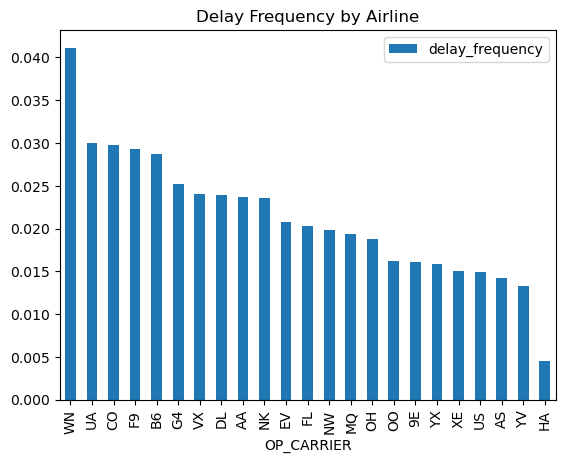

In [5]:
delay_freq_pd = delay_freq.toPandas()
delay_freq_pd.plot.bar(x='OP_CARRIER', y='delay_frequency', title="Delay Frequency by Airline")


In [12]:
#Top Airlines by Cancellation Rate

cancel_rate = df.groupBy("OP_CARRIER") \
                .agg(avg("CANCELLED").alias("cancellation_rate")) \
                .orderBy(col("cancellation_rate").desc())

cancel_rate.show()



+----------+--------------------+
|OP_CARRIER|   cancellation_rate|
+----------+--------------------+
|        OH| 0.05132743362831858|
|        MQ| 0.04418907806436678|
|        YX|0.039542461610512905|
|        EV| 0.03691849209987453|
|        XE|0.031272852312453435|
|        9E|0.029118610115056856|
|        YV|0.025570600455357438|
|        NK| 0.02522330932493374|
|        B6|0.023652843983930423|
|        OO|0.022127696997314563|
|        AA| 0.02042399519516573|
|        US| 0.01653776867548804|
|        UA| 0.01528422562819132|
|        WN| 0.01389721704413072|
|        VX|0.011777842051806361|
|        FL|0.011582204340175484|
|        CO|0.010520446871482764|
|        G4|0.010391993099387981|
|        F9|0.010282579198867324|
|        DL|0.009558313717362231|
+----------+--------------------+
only showing top 20 rows



<Axes: title={'center': 'Cancellation Rate by Airline'}, xlabel='OP_CARRIER'>

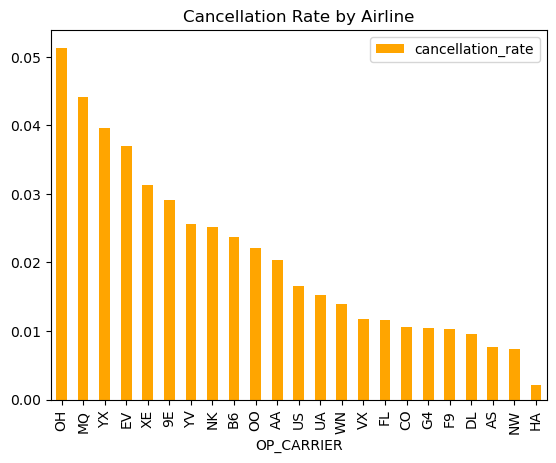

In [13]:
cancel_rate_pd = cancel_rate.toPandas()
cancel_rate_pd.plot.bar(x='OP_CARRIER', y='cancellation_rate', color='orange', title="Cancellation Rate by Airline")

In [15]:
#Year-over-Year Delays

yearly_delays = df.groupBy("YEAR") \
                  .agg(avg("DEP_DELAY").alias("avg_dep_delay")) \
                  .orderBy("YEAR")

yearly_delays.show()


+----+-------------------+
|YEAR|      avg_dep_delay|
+----+-------------------+
|2009|-1.6626938177933428|
|2010| -1.338274118232539|
|2011|-1.4320517824750252|
|2012|-1.5666079206420076|
|2013|-1.4041804565201956|
|2014|-1.3170113754455133|
|2015|-1.5266120865210568|
|2016|-1.8547952526121343|
|2017| -2.070962962141419|
|2018|-2.2586639417379373|
+----+-------------------+



<Axes: title={'center': 'Yearly Avg Departure Delay'}, xlabel='YEAR'>

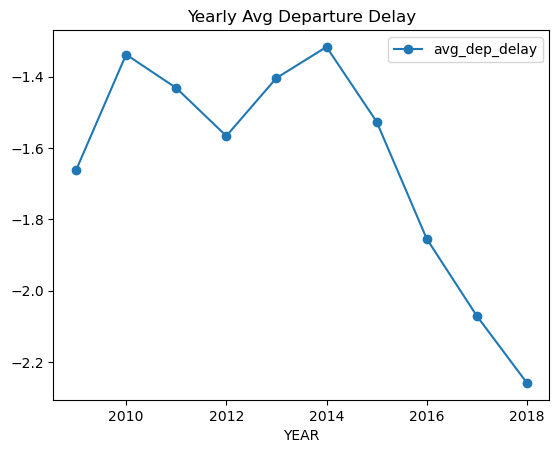

In [16]:
yearly_delays.toPandas().plot(x='YEAR', y='avg_dep_delay', marker='o', title="Yearly Avg Departure Delay")

In [18]:
# Time-of-Day Delay Trends

# Create departure hour column
df = df.withColumn("DEP_HOUR", (col("CRS_DEP_TIME") / 100).cast("int"))

hourly_delays = df.groupBy("DEP_HOUR") \
                  .agg(avg("DEP_DELAY").alias("avg_dep_delay")) \
                  .orderBy("DEP_HOUR")

hourly_delays.show()



+--------+-------------------+
|DEP_HOUR|      avg_dep_delay|
+--------+-------------------+
|       0| -2.085099473946269|
|       1| -3.330336740074831|
|       2|-3.9855365308943953|
|       3| -4.714992927864215|
|       4| -4.741921947125472|
|       5|-3.3155326296423517|
|       6| -3.186198404184368|
|       7|-2.9081090595249974|
|       8|-2.4327997472589025|
|       9|-1.9906665845730263|
|      10|-1.7570628549506324|
|      11|-1.6232557278407775|
|      12|-1.4560365114686584|
|      13|-1.1868248011786828|
|      14|-0.8741376596526107|
|      15| -0.844678431558247|
|      16|-0.8514600708159833|
|      17|-0.9745014322323764|
|      18| -1.030998054425054|
|      19|-0.9769163089050099|
+--------+-------------------+
only showing top 20 rows



<Axes: title={'center': 'Avg Delay by Hour'}, xlabel='DEP_HOUR'>

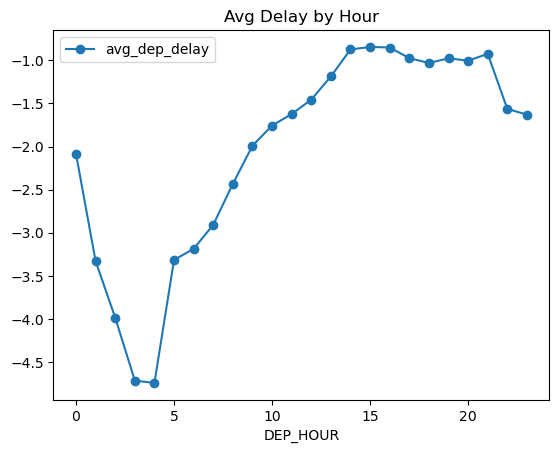

In [19]:
hourly_delays.toPandas().plot(x='DEP_HOUR', y='avg_dep_delay', marker='o', title="Avg Delay by Hour")


In [30]:
#Airports vs. Delay Types

# Alternative: Avg departure delay by airport
airport_delay_avg = df.groupBy("ORIGIN") \
                      .agg(avg("DEP_DELAY").alias("avg_dep_delay")) \
                      .orderBy(col("avg_dep_delay").desc()) \
                      .limit(10)

airport_delay_avg.show()



+------+--------------------+
|ORIGIN|       avg_dep_delay|
+------+--------------------+
|   YNG|                15.0|
|   OGD|  1.6744186046511629|
|   MDW|  1.6451857883997767|
|   DAL|  1.5584210185065115|
|   SCK|   1.450765864332604|
|   HOU|  1.4281358056860356|
|   GUM|  0.6316003249390739|
|   OAK|  0.4878439165105866|
|   BWI| 0.11327759197324415|
|   HGR|0.011627906976744186|
+------+--------------------+



<Axes: title={'center': 'Top 10 Airports by Avg Departure Delay'}, xlabel='ORIGIN'>

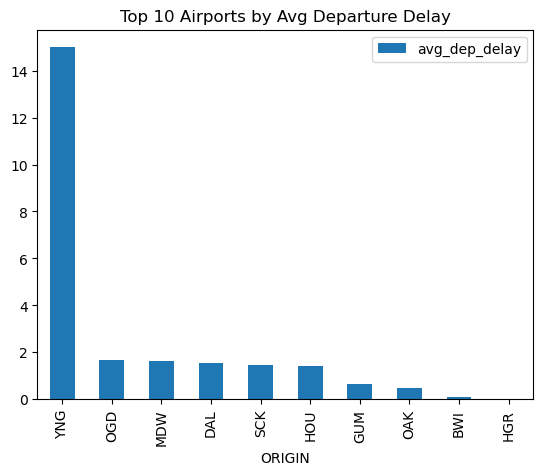

In [31]:
airport_delay_avg.toPandas().plot.bar(x='ORIGIN', y='avg_dep_delay', title='Top 10 Airports by Avg Departure Delay')